# 7. Hồ sơ người chơi và trực quan hóa

Nếu thiếu tệp trung gian, chạy lần lượt notebook 04 đến phần ngay trước file này.

Muốn chạy toàn bộ trong một kernel: [mở notebook 00](00_Gamer_Behavior_Clustering.ipynb).

<details><summary>Danh sách tám phần</summary>

- [1. Tìm hiểu bài toán và dữ liệu](01_data_understanding.ipynb)

- [2. Thống kê và khám phá dữ liệu (EDA)](02_statistics_eda.ipynb)

- [3. Kiểm tra và làm sạch dữ liệu](03_data_cleaning.ipynb)

- [4. Chia dữ liệu và chuẩn hóa](04_data_transformation.ipynb)

- [5. Ward, K-Means và cách kết hợp](05_clustering.ipynb)

- [6. Đánh giá holdout và độ nhạy](06_model_evaluation.ipynb)

- [7. Hồ sơ người chơi và trực quan hóa](07_player_profiling.ipynb)

- [8. Gán người chơi và đề xuất chiến lược](08_prediction_strategy.ipynb)

</details>

## Khởi tạo và đọc dữ liệu

In [1]:
from pathlib import Path
import os, sys, json, hashlib
import numpy as np
import pandas as pd
import joblib
from IPython.display import display, Markdown

# Tìm gốc dự án khi mở từ thư mục notebooks/, gamer_profiling/ hoặc workspace.
cwd = Path.cwd().resolve()
candidates = [cwd, *cwd.parents, cwd / "gamer_profiling"]
ROOT = next((p for p in candidates if (p / "gamer_clustering.py").is_file()), None)
if ROOT is None:
    raise FileNotFoundError("Mở notebook từ thư mục dự án gamer_profiling hoặc notebooks/.")
NBOUT = Path(os.environ.get("GAMER_NOTEBOOK_OUTPUT", str(ROOT / "outputs/notebook/latest")))
NBOUT.mkdir(parents=True, exist_ok=True)
os.environ.setdefault("MPLCONFIGDIR", str(NBOUT / ".matplotlib"))
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from gamer_clustering import clean_features, centers_from_labels, metrics, choose_k
from sklearn.cluster import KMeans
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split
from sklearn.metrics import (pairwise_distances, silhouette_score, silhouette_samples,
                             davies_bouldin_score, adjusted_rand_score)
from sklearn.metrics.pairwise import pairwise_distances_argmin
from sklearn.decomposition import PCA
from scipy.cluster.hierarchy import linkage, cut_tree, dendrogram
from threadpoolctl import threadpool_limits
import matplotlib.pyplot as plt
import seaborn as sns

# Module .py dùng Agg khi chạy batch; trong notebook cần hiển thị hình ngay dưới ô code.
get_ipython().run_line_magic("matplotlib", "inline")
thread_limit = threadpool_limits(limits=2)
sns.set_theme(style="whitegrid", font="DejaVu Sans", context="notebook")
pd.set_option("display.max_columns", 20)
pd.set_option("display.precision", 4)
SEED = 42
FEATURES = ["PlayTimeHours", "SessionsPerWeek", "AvgSessionDurationMinutes",
            "PlayerLevel", "AchievementsUnlocked"]
METHODS = ["KMeans", "Ward", "Ward_KMeans"]
SOURCE = ROOT / "data/online_gaming_behavior_dataset.csv"
df = pd.read_csv(SOURCE)
reference = json.loads((ROOT / "outputs/summary.json").read_text(encoding="utf-8"))

def require(name, previous):
    path = NBOUT / name
    if not path.is_file():
        raise FileNotFoundError(f"Chưa có {name}. Chạy notebook {previous} trước, hoặc Run All notebook 00.")
    return path

def save_plot(name):
    plt.tight_layout()
    plt.savefig(NBOUT / name, dpi=150, bbox_inches="tight")
    plt.show()
    plt.close()

Cần mô hình từ notebook 06. Dùng mô hình fit train để gán toàn bộ dữ liệu và mô tả hồ sơ.
Các bảng toàn bộ dân số này không phải đánh giá ngoài mẫu. Tên cụm là mô tả tương đối,
số hiệu cụm không phải thứ hạng; nhóm không được tự động gọi là High-Spenders.

In [2]:
artifact = joblib.load(require("player_model.joblib", "06_model_evaluation.ipynb"))
X = clean_features(df)
Z_all = artifact["prep"].transform(X)
labels = artifact["model"].predict(Z_all)
players = df.assign(cluster=labels)
profile = players.groupby("cluster")[FEATURES].mean()
profile["count"] = players.groupby("cluster").size()
profile["share_pct"] = profile["count"] / len(players) * 100
profile["purchase_rate"] = players.groupby("cluster").InGamePurchases.mean()
freq = profile.SessionsPerWeek.rank(pct=True)
duration = profile.AvgSessionDurationMinutes.rank(pct=True)
profile["profile"] = [
    ("Chơi thường xuyên" if freq[c] > .5 else "Chơi ít phiên") + ", " +
    ("phiên dài" if duration[c] > .5 else "phiên ngắn") for c in profile.index]
display(profile)
assert profile["count"].sum() == len(df)
profile.to_csv(NBOUT / "cluster_profiles.csv", encoding="utf-8-sig")
players.to_csv(NBOUT / "player_assignments.csv", index=False, encoding="utf-8-sig")
artifact["cluster_names"] = profile["profile"].to_dict()
joblib.dump(artifact, NBOUT / "player_model.joblib")

,PlayTimeHours,SessionsPerWeek,AvgSessionDurationMinutes,PlayerLevel,AchievementsUnlocked,count,share_pct,purchase_rate,profile
cluster,,,,,,,,,
0,6.5497,6.6017,62.8103,68.9703,35.6209,5315,13.2762,0.2036,"Chơi ít phiên, phiên ngắn"
1,7.0248,12.8650,132.4144,27.5363,33.4307,4964,12.3995,0.2025,"Chơi thường xuyên, phiên dài"
2,17.1040,5.8185,133.4981,29.6941,16.5355,5354,13.3736,0.1892,"Chơi ít phiên, phiên dài"
3,17.2749,11.3410,59.0600,71.1918,12.9503,5015,12.5269,0.1936,"Chơi thường xuyên, phiên ngắn"
4,17.0324,10.8286,130.6931,73.8669,36.1437,4838,12.0847,0.2013,"Chơi thường xuyên, phiên dài"
5,6.4777,9.3634,131.1950,71.7028,12.3751,4775,11.9274,0.2080,"Chơi ít phiên, phiên dài"
6,6.9532,9.6208,54.9924,26.2755,12.8818,4839,12.0872,0.2085,"Chơi ít phiên, phiên ngắn"
7,17.5337,9.8423,54.3127,28.7270,35.8435,4934,12.3245,0.2015,"Chơi thường xuyên, phiên ngắn"


['C:\\Bop\\New folder\\gamer_profiling\\outputs\\notebook\\validation_bd40b6e5a2\\modular\\player_model.joblib']

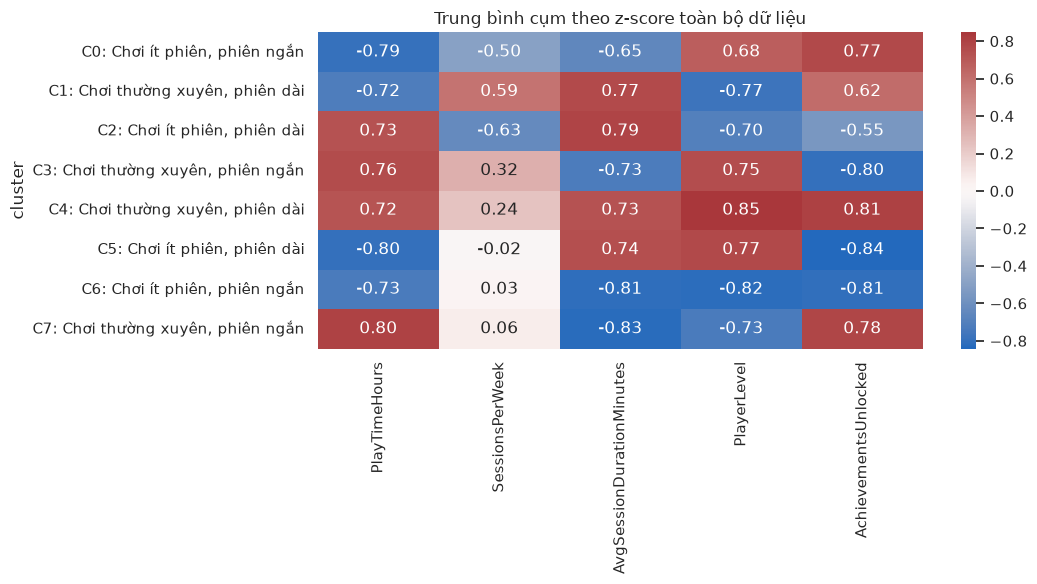

In [3]:
normalized = (profile[FEATURES] - X.mean()) / X.std(ddof=0)
plt.figure(figsize=(11, 6))
sns.heatmap(normalized, annot=True, fmt=".2f", cmap="vlag", center=0,
            yticklabels=[f"C{c}: {profile.loc[c, 'profile']}" for c in profile.index])
plt.title("Trung bình cụm theo z-score toàn bộ dữ liệu")
save_plot("07_profiles.png")

Màu nóng: cao hơn trung bình chung; màu lạnh: thấp hơn. Các cụm có thể trùng tên mô tả,
vì tên chỉ tóm tắt tần suất × thời lượng, còn mô hình học năm biến. Dùng ID cụm để phân biệt.
PCA chỉ là hình chiếu sau học, không phải đầu vào của phân cụm.

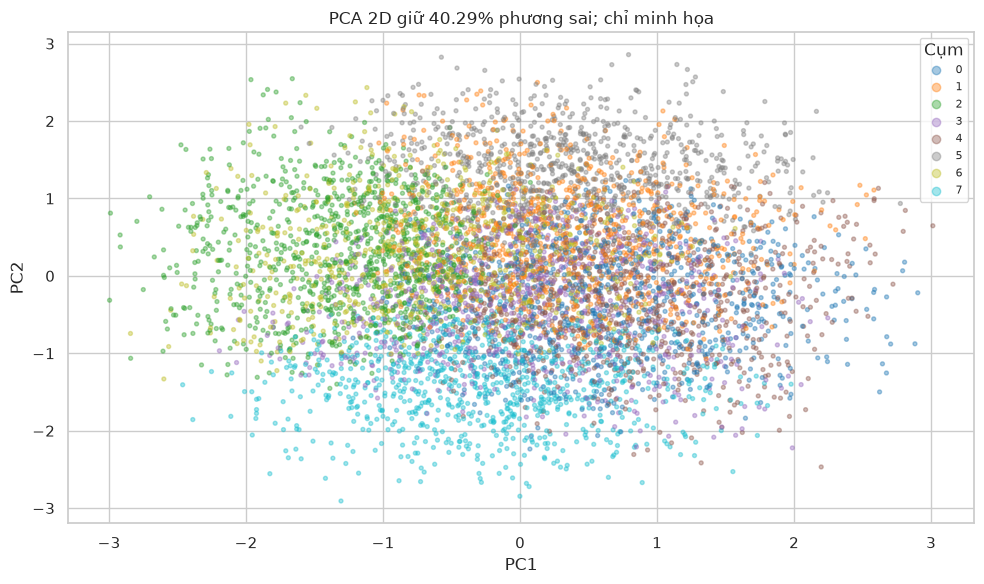

In [4]:
pca = PCA(n_components=2).fit(Z_all)
xy = pca.transform(Z_all)
take = np.random.default_rng(SEED).choice(len(df), min(7000, len(df)), replace=False)
plt.figure(figsize=(10, 6))
scatter = plt.scatter(xy[take, 0], xy[take, 1], c=labels[take], cmap="tab10", s=8, alpha=.4)
plt.legend(*scatter.legend_elements(), title="Cụm", fontsize=8)
plt.xlabel("PC1"); plt.ylabel("PC2")
plt.title(f"PCA 2D giữ {pca.explained_variance_ratio_.sum():.2%} phương sai; chỉ minh họa")
save_plot("07_pca.png")

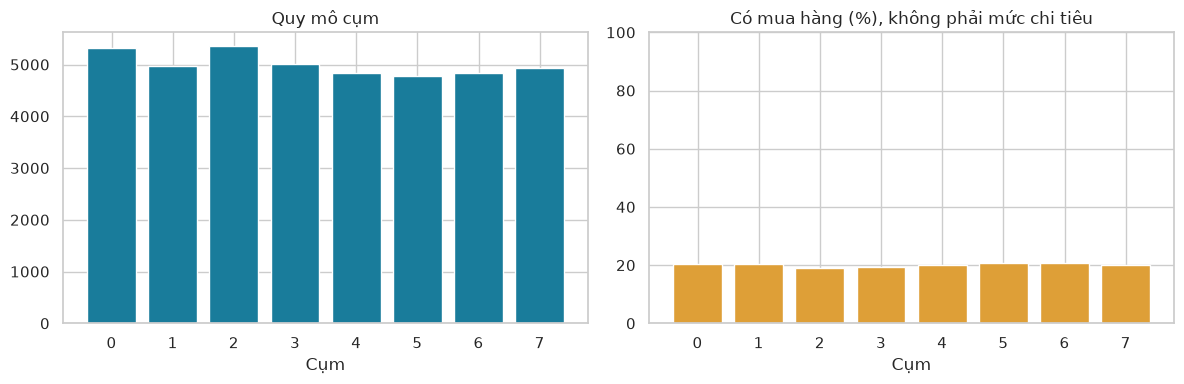

EngagementLevel,High,Low,Medium
cluster,,,
0,0.0534,0.3910,0.5556
1,0.5977,0.0570,0.3453
2,0.2079,0.3214,0.4707
3,0.1470,0.2921,0.5609
4,0.5205,0.0746,0.4049
5,0.3941,0.1516,0.4542
6,0.0833,0.4042,0.5125
7,0.0876,0.3518,0.5606


EngagementLevel chỉ được đối chiếu **sau học**. Tỷ lệ có mua không chứng minh nhóm chi tiêu cao hoặc sẽ phản ứng tốt hơn với ưu đãi.

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].bar(profile.index, profile["count"], color="#197c9b")
axes[0].set_title("Quy mô cụm"); axes[0].set_xlabel("Cụm")
axes[1].bar(profile.index, profile.purchase_rate * 100, color="#de9f37")
axes[1].set_ylim(0, 100); axes[1].set_title("Có mua hàng (%), không phải mức chi tiêu")
axes[1].set_xlabel("Cụm")
save_plot("07_sizes_purchases.png")
engagement = pd.crosstab(players.cluster, players.EngagementLevel, normalize="index")
display(engagement)
display(Markdown("EngagementLevel chỉ được đối chiếu **sau học**. "
                 "Tỷ lệ có mua không chứng minh nhóm chi tiêu cao hoặc sẽ phản ứng tốt hơn với ưu đãi."))